# Heart Disease Risk Predictor (FNN)
**Module:** ITLPA701, Python and Fundamentals of AI | **Approach:** Deep Learning (Feedforward Neural Network)

## 1. Problem
Predict whether a patient is likely to have heart disease from clinical measurements (age, blood pressure, cholesterol, ECG, heart rate and others). This is a binary classification problem on tabular data.

## 2. Environment and functionalities
| Package | Purpose |
|---|---|
| pandas, numpy | loading, cleaning and handling the data |
| scikit-learn | train/test split, scaling, evaluation metrics |
| TensorFlow / Keras | building and training the FNN |
| matplotlib, seaborn | training curves and confusion matrix |
| joblib | saving the scaler and settings |
| gradio | web demo interface (`app.py`) |

Python 3.14 in a virtual environment (`venv`) in VS Code. Packages are listed in `requirements.txt`.

## 3. Data source
Heart Failure Prediction dataset from Kaggle (`heart.csv`): 918 patients, 11 features and 1 target (`HeartDisease`).

In [1]:
import pandas as pd, numpy as np, tensorflow as tf
print("TensorFlow:", tf.__version__)

df = pd.read_csv("data/heart.csv")
print(df.shape)
df.head()

TensorFlow: 2.22.0-rc0
(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
print("Columns:", df.columns.tolist())
print()
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget counts:\n", df["HeartDisease"].value_counts())
print("\nZero values:\n", (df[["RestingBP", "Cholesterol"]] == 0).sum())

Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

Missing values:
 Age               0
Sex             

## Data preprocessing

| Step | What I did | Why |
|---|---|---|
| Inspect | Checked shape, data types, missing values and target balance | To know what needed cleaning (918 rows, 12 columns, no empty cells) |
| Impossible values | Dropped 1 row with RestingBP = 0 and treated 172 Cholesterol = 0 values as missing | A living patient cannot have 0 blood pressure or 0 cholesterol, so these are recording errors |
| Encoding | One-hot encoded Sex, ChestPainType, RestingECG, ExerciseAngina and ST_Slope | Neural networks only accept numbers |
| Split | 80% train (733) and 20% test (184), stratified, random_state = 42 | Test data stays unseen; stratify keeps the same class balance in both parts |
| Missing cholesterol | Filled with the median of the training set only | Median is not affected by extreme values; using only the training set avoids data leakage |
| Scaling | StandardScaler fitted on the training set only | Features have very different ranges (Age vs Cholesterol), and the network trains badly without scaling |
| Saved | scaler, feature columns and cholesterol median in `models/` | The demo app needs exactly the same steps for new patients |

In [3]:
# Drop the 1 row with RestingBP = 0, and treat Cholesterol = 0 as missing
df = df[df["RestingBP"] != 0].copy()
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)

print(df.shape)
print("Missing Cholesterol:", df["Cholesterol"].isnull().sum())

(917, 12)
Missing Cholesterol: 171


In [4]:
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print(df_encoded.shape)
df_encoded.head()

(917, 16)


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0.0,0,1,1,0,0,1,0,0,0,1
1,49,160,180.0,0,156,1.0,1,0,0,1,0,1,0,0,1,0
2,37,130,283.0,0,98,0.0,0,1,1,0,0,0,1,0,0,1
3,48,138,214.0,0,108,1.5,1,0,0,0,0,1,0,1,1,0
4,54,150,195.0,0,122,0.0,0,1,0,1,0,1,0,0,0,1


In [5]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Use the TRAIN median only, so no test information leaks into training
chol_median = X_train["Cholesterol"].median()
X_train = X_train.fillna({"Cholesterol": chol_median})
X_test = X_test.fillna({"Cholesterol": chol_median})

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Missing left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Train: (733, 15) Test: (184, 15)
Missing left: 0


In [6]:
from sklearn.preprocessing import StandardScaler
import joblib, os

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

os.makedirs("models", exist_ok=True)
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(X.columns.tolist(), "models/feature_columns.pkl")
joblib.dump(chol_median, "models/chol_median.pkl")

print("Scaled shapes:", X_train_scaled.shape, X_test_scaled.shape)
print("\nTarget balance (train):\n", y_train.value_counts())

Scaled shapes: (733, 15) (184, 15)

Target balance (train):
 HeartDisease
1    405
0    328
Name: count, dtype: int64


## 4. Model selection and parameters

**Why an FNN?** The data is tabular (rows of patient measurements), which is what a feedforward neural network (FNN) is designed for. A CNN is for images and an RNN is for sequences, so neither fits this problem.

| Setting | Value | Why |
|---|---|---|
| Hidden layers | 32 then 16 neurons | The dataset is small (918 rows), so a small network is enough and overfits less |
| Hidden activation | ReLU | Standard choice, trains quickly |
| Output layer | 1 neuron, sigmoid | Gives a probability between 0 and 1 for heart disease |
| Dropout | 0.3 and 0.2 | Randomly switches off neurons during training to reduce overfitting |
| Optimizer | Adam, learning rate 0.001 | Reliable default optimizer |
| Loss | Binary cross-entropy | Standard loss for two-class problems |
| Batch size | 32 | Small batches suit a small dataset |
| Early stopping | patience 15, restore best weights | Stops when validation loss stops improving and keeps the best version |
| Validation split | 20% of training data | Used to monitor overfitting during training |

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

model.save("models/heart_model.keras")
print("Epochs trained:", len(history.history["loss"]))

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5410 - loss: 0.6901 - val_accuracy: 0.6735 - val_loss: 0.6164
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6877 - loss: 0.5837 - val_accuracy: 0.7823 - val_loss: 0.5461
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7765 - loss: 0.5179 - val_accuracy: 0.7891 - val_loss: 0.5010
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8140 - loss: 0.4679 - val_accuracy: 0.7959 - val_loss: 0.4753
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8208 - loss: 0.4495 - val_accuracy: 0.8095 - val_loss: 0.4604
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8447 - loss: 0.4053 - val_accuracy: 0.8231 - val_loss: 0.4543
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8447 - loss: 0.3896 - val_accuracy: 0.8231 - val_loss: 0.4529
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8549 - loss: 0.3713 - val_accuracy: 0.8163 - 

## 5. Evaluation

**Metrics chosen:** accuracy, precision, recall, F1-score and a confusion matrix, because this is a two-class classification problem. Recall is the most important one here, because missing a patient who has heart disease is worse than a false alarm.

**Results on the test set (184 unseen patients, threshold 0.5):**
Accuracy 0.897, Precision 0.928, Recall 0.882, F1-score 0.905.

**Interpretation:** the model is correct about 9 times out of 10. When it predicts heart disease it is right 93% of the time, and it finds 88% of the patients who really have it (12 of 102 were missed). The training curves show validation loss becoming flat while training loss keeps falling, which is mild overfitting. Dropout and early stopping reduced this.

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Accuracy : 0.891
Precision: 0.902
Recall   : 0.902
F1-score : 0.902

              precision    recall  f1-score   support

  No disease       0.88      0.88      0.88        82
     Disease       0.90      0.90      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



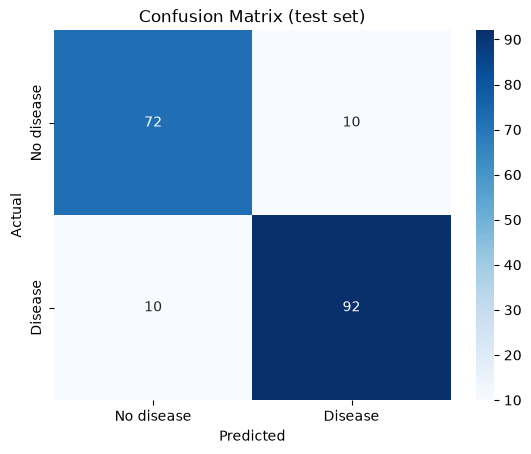

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns

y_prob = model.predict(X_test_scaled).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (test set)")
plt.show()

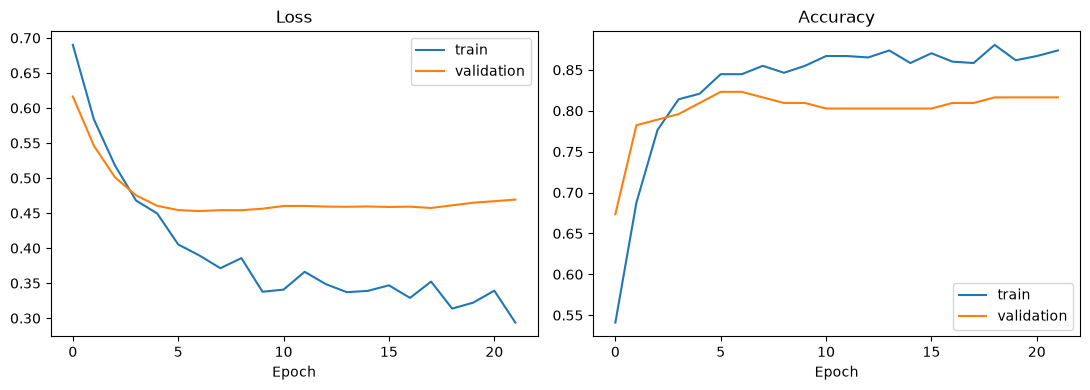

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.show()

## 6. Tuning based on the results

Recall was lower than precision, so I tested lower decision thresholds on the validation data (not the test set). Recall rose steadily as the threshold fell (0.880 at 0.5 to 0.904 at 0.4) while F1 stayed almost the same, so I chose **0.4**.

**Effect on the test set:** missed patients fell from 12 to 10 (recall 0.882 to 0.902), false alarms rose from 7 to 10 (precision 0.928 to 0.902), and F1 stayed about the same (0.905 to 0.902). I accepted slightly lower precision because missing a sick patient is more serious in a medical screening problem.

In [11]:
n_val = int(len(X_train_scaled) * 0.2)
X_val = X_train_scaled[-n_val:]
y_val = y_train.iloc[-n_val:]
val_prob = model.predict(X_val).ravel()

rows = []
for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    p = (val_prob >= t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(y_val, p),
                 "precision": precision_score(y_val, p),
                 "recall": recall_score(y_val, p),
                 "f1": f1_score(y_val, p)})

pd.DataFrame(rows).round(3)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


,threshold,accuracy,precision,recall,f1
0,0.50,0.829,0.822,0.892,0.855
1,0.45,0.829,0.815,0.904,0.857
2,0.40,0.829,0.809,0.916,0.859
3,0.35,0.815,0.792,0.916,0.849
4,0.30,0.808,0.778,0.928,0.846


Before (0.5) -> After (0.4)
Accuracy  : 0.891 -> 0.880
Precision : 0.902 -> 0.877
Recall    : 0.902 -> 0.912
F1-score  : 0.902 -> 0.894


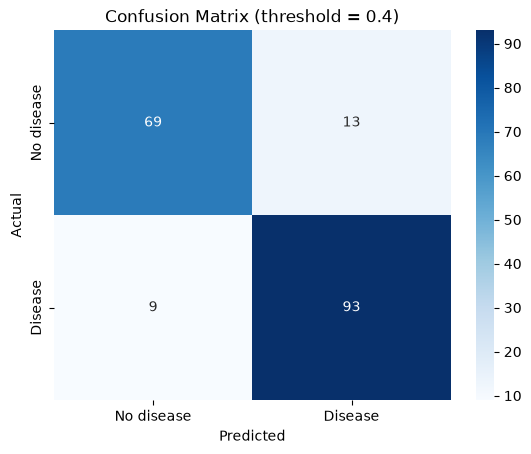

Saved models/config.json


In [12]:
import json

THRESHOLD = 0.4   # chosen from the validation table above

y_pred_new = (y_prob >= THRESHOLD).astype(int)

print("Before (0.5) -> After ({})".format(THRESHOLD))
for name, fn in [("Accuracy", accuracy_score), ("Precision", precision_score),
                 ("Recall", recall_score), ("F1-score", f1_score)]:
    print(f"{name:10s}: {fn(y_test, y_pred):.3f} -> {fn(y_test, y_pred_new):.3f}")

cm_new = confusion_matrix(y_test, y_pred_new)
sns.heatmap(cm_new, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (threshold = {THRESHOLD})")
plt.show()

config = {
    "threshold": THRESHOLD,
    "architecture": "Dense(32,relu)-Dropout(0.3)-Dense(16,relu)-Dropout(0.2)-Dense(1,sigmoid)",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 32,
    "early_stopping_patience": 15,
    "test_size": 0.2,
    "random_state": 42
}
with open("models/config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved models/config.json")

## 7. Demonstration
The model is deployed as a Gradio web app (`app.py`). It loads the saved model, scaler, feature columns, cholesterol median and `config.json` from the `models/` folder, so the application can be reproduced. Run it with `python app.py`.

## 8. Responsible use
**Limitation 1: small, limited data.** The model was trained on only 918 patients from one dataset, so it may not work equally well for people of different ages, sexes or regions, including Rwandan patients. A wrong prediction could give someone false reassurance.
**How to reduce it:** train on larger and more diverse data, test the model separately on each group, and always have a doctor confirm the result.

**Limitation 2: limited age range.** The model learned only from patients aged 28 to 77, so its predictions for younger or older people are less reliable. The app shows a warning when the age is outside this range.
**How to reduce it:** collect and train on data that includes more ages, such as children and people over 80. Test the model separately on each age group, to see where it performs worse. Until then, the app should keep the warning and tell users to see a doctor, and a doctor must always confirm the result.


### Data analysis: chest pain type vs heart disease
In this dataset, 79.0% of patients with ASY (asymptomatic) chest pain type have heart disease, compared with 13.9% for ATA, 35.1% for NAP and 43.5% for TA (only 46 patients). ChestPainType is therefore a strong feature, so I kept it in the model. This is a pattern in the data, not a medical cause, and it could mean the model depends too heavily on one feature.

In [13]:
summary = df.groupby("ChestPainType")["HeartDisease"].agg(["count", "mean"])
summary["mean"] = (summary["mean"] * 100).round(1)
summary.columns = ["patients", "% with heart disease"]
summary

,patients,% with heart disease
ChestPainType,,
ASY,496,79.0
ATA,173,13.9
NAP,202,35.1
TA,46,43.5


In [14]:
import pandas as pd

df = pd.read_csv("data/heart.csv")
df["Age"].min(), df["Age"].max()

(np.int64(28), np.int64(77))